In [ ]:
import pandas as pd
import networkx as nx

# load nodes and edges
nodes = pd.read_excel("facebook_sna_600_users_generated.xlsx", sheet_name="nodes")
edges = pd.read_excel("facebook_sna_600_users_generated.xlsx", sheet_name="edges")

print(nodes)
print(edges)

     username  followers  following  posts
0      user_1       4284       2931    310
1      user_2        165       1411    347
2      user_3       1419       4262    635
3      user_4       2012       1417    724
4      user_5       3940       2030    320
..        ...        ...        ...    ...
595  user_596       1883        353    338
596  user_597       1812       4977    371
597  user_598       1590       4436    151
598  user_599       4109       1685    499
599  user_600       4302       3717    572

[600 rows x 4 columns]
     source_user target_user interaction_type
0       user_360    user_491             like
1       user_539    user_503            share
2       user_479    user_428           follow
3        user_95     user_18           follow
4       user_104    user_307          comment
...          ...         ...              ...
2984    user_480    user_263           follow
2985    user_100    user_553          comment
2986     user_21    user_595             like


In [ ]:
nodes.columns

Index(['username', 'followers', 'following', 'posts'], dtype='object')

In [ ]:
edges.columns

Index(['source_user', 'target_user', 'interaction_type'], dtype='object')

In [ ]:
G = nx.Graph()

# add nodes
for user in nodes["username"]:
    G.add_node(user)

# add edges
for i in range(len(edges)):
    source = edges.loc[i, "source_user"]
    target = edges.loc[i, "target_user"]

    G.add_edge(source, target)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 600
Edges: 2966


In [ ]:
degree = nx.degree_centrality(G)

betweenness = nx.betweenness_centrality(G)

closeness = nx.closeness_centrality(G)

eigenvector = nx.eigenvector_centrality(G, max_iter=1000)

In [ ]:
results = pd.DataFrame({
    "username": list(degree.keys()),
    "degree": list(degree.values()),
    "betweenness": [betweenness[n] for n in degree.keys()],
    "closeness": [closeness[n] for n in degree.keys()],
    "eigenvector": [eigenvector[n] for n in degree.keys()]
})

print(results.head())

  username    degree  betweenness  closeness  eigenvector
0   user_1  0.015025     0.002361   0.332224     0.038909
1   user_2  0.010017     0.001218   0.307495     0.022726
2   user_3  0.010017     0.001134   0.302220     0.019577
3   user_4  0.020033     0.004948   0.348458     0.050611
4   user_5  0.015025     0.002735   0.331489     0.035134


In [ ]:
results["rank_score"] = (
    results["degree"] +
    results["betweenness"] +
    results["closeness"] +
    results["eigenvector"]
)

In [ ]:
top_users = results.sort_values(by="rank_score", ascending=False)

print(top_users.head(10))

     username    degree  betweenness  closeness  eigenvector  rank_score
396  user_397  0.033389     0.012097   0.371128     0.085874    0.502488
430  user_431  0.035058     0.012938   0.368389     0.085733    0.502119
109  user_110  0.033389     0.012266   0.366137     0.078973    0.490765
168  user_169  0.028381     0.008619   0.366810     0.079979    0.483787
197  user_198  0.031720     0.010495   0.363471     0.076638    0.482324
184  user_185  0.028381     0.009551   0.366361     0.074892    0.479184
479  user_480  0.030050     0.009877   0.363250     0.074229    0.477407
234  user_235  0.031720     0.011087   0.361715     0.072193    0.476715
355  user_356  0.026711     0.007595   0.364577     0.073861    0.472744
20    user_21  0.028381     0.009388   0.361934     0.072557    0.472259


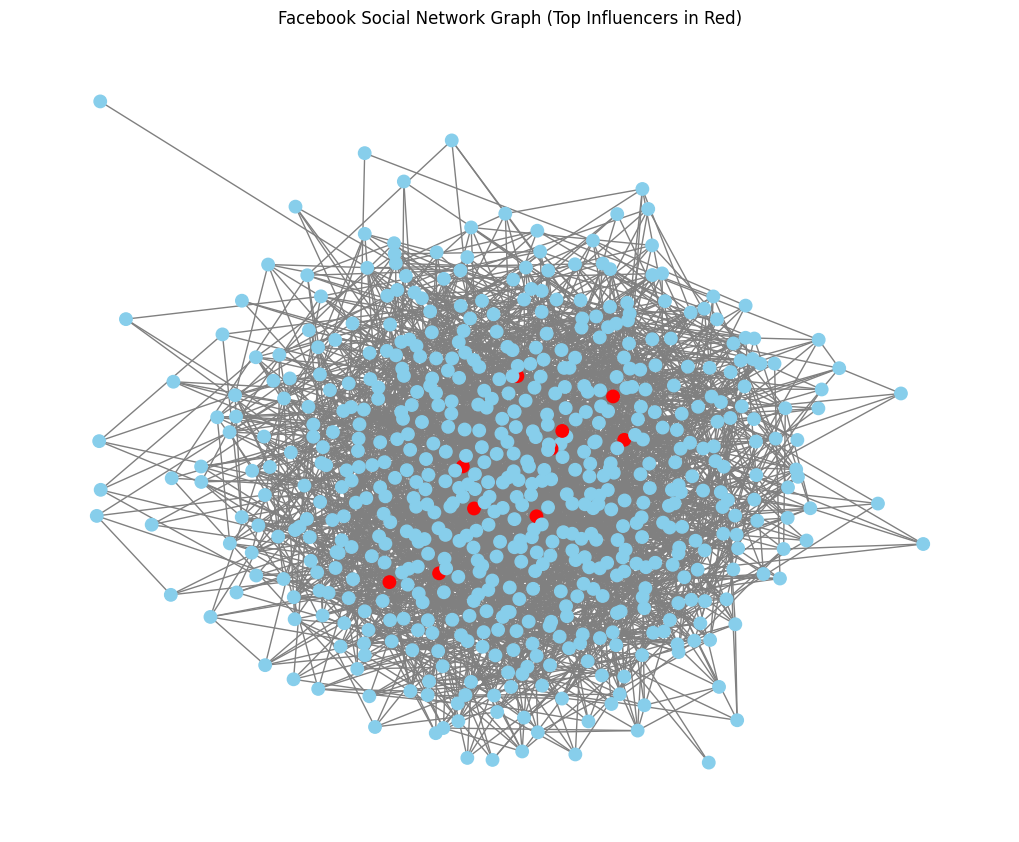

In [ ]:
import matplotlib.pyplot as plt

top10 = top_users.head(10)["username"]

node_colors = []
for node in G.nodes():
    if node in list(top10):
        node_colors.append("red")
    else:
        node_colors.append("skyblue")

plt.figure(figsize=(10,8))

pos = nx.spring_layout(G)

nx.draw(G, pos,
        node_color=node_colors,
        node_size=80,
        edge_color="gray",
        with_labels=False)

plt.title("Facebook Social Network Graph (Top Influencers in Red)")
plt.show()

In [ ]:
good_comments = [
"Great video!",
"Excellent content",
"Very helpful post",
"I really like this",
"Amazing work",
"Very informative",
"Love this content",
"Keep it up",
"This is fantastic",
"Very interesting"
]

bad_comments = [
"This is terrible",
"I don't like this",
"Waste of time",
"Very bad content",
"Not useful at all",
"Poor explanation",
"This is boring",
"Disappointing post",
"I hate this",
"Very confusing"
]

In [ ]:
import pandas as pd
import random

file = "facebook_sna_600_users_generated.xlsx"

profiles = pd.read_excel(file, sheet_name="nodes")
edges = pd.read_excel(file, sheet_name="edges")

edges["comment_text"] = ""

for i in range(len(edges)):
    if edges.loc[i,"interaction_type"] == "comment":
        edges.loc[i,"comment_text"] = random.choice(good_comments + bad_comments)

with pd.ExcelWriter("facebook_sentiment_dataset.xlsx") as writer:
    profiles.to_excel(writer, sheet_name="nodes", index=False)
    edges.to_excel(writer, sheet_name="edges", index=False)

In [ ]:
!pip install textblob

In [ ]:
import pandas as pd

edges = pd.read_excel("facebook_sentiment_dataset.xlsx", sheet_name="edges")

edges.head()

,source_user,target_user,interaction_type,comment_text
0,user_360,user_491,like,NaN
1,user_539,user_503,share,NaN
2,user_479,user_428,follow,NaN
3,user_95,user_18,follow,NaN
4,user_104,user_307,comment,Very informative


In [ ]:
from textblob import TextBlob

def analyze_sentiment(text):

    if text == "" or pd.isna(text):
        return "No Comment"

    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0:
        return "Positive"
    else:
        return "Negative"


edges["predicted_sentiment"] = edges["comment_text"].apply(analyze_sentiment)

In [ ]:
edges[["comment_text","predicted_sentiment"]].head(10)

,comment_text,predicted_sentiment
0,NaN,No Comment
1,NaN,No Comment
2,NaN,No Comment
3,NaN,No Comment
4,Very informative,Positive
5,NaN,No Comment
6,NaN,No Comment
7,NaN,No Comment
8,NaN,No Comment
9,NaN,No Comment


In [ ]:
edges["predicted_sentiment"].value_counts()

,count
predicted_sentiment,
No Comment,2215
Negative,419
Positive,355


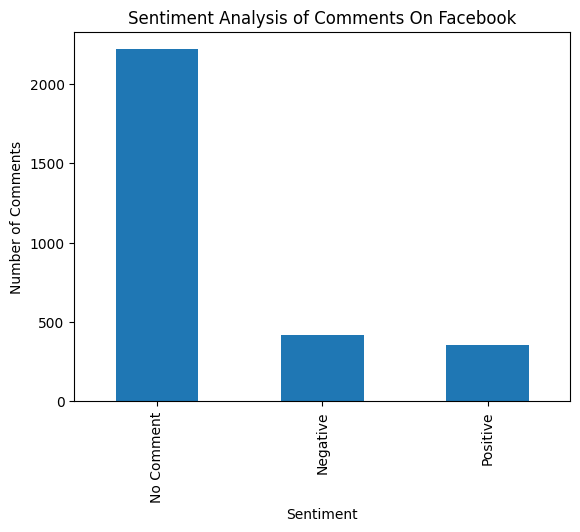

In [ ]:
import matplotlib.pyplot as plt

edges["predicted_sentiment"].value_counts().plot(kind="bar")

plt.title("Sentiment Analysis of Comments On Facebook")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")

plt.show()

In [ ]:
import pandas as pd

In [ ]:
# Load nodes sheet (user data)
df = pd.read_excel("facebook_sna_600_users_generated.xlsx", sheet_name="nodes")

df.head()

,username,followers,following,posts
0,user_1,4284,2931,310
1,user_2,165,1411,347
2,user_3,1419,4262,635
3,user_4,2012,1417,724
4,user_5,3940,2030,320


In [ ]:
def bot_score(row):
    score = 0

    # Rule 1: Following >> Followers
    if row['following'] > 1000:
        score += 1

    if row['followers'] < 100:
        score += 1

    # Rule 2: High posting activity
    if row['posts'] > 300:
        score += 1

    # Rule 3: Low influence (if centrality exists)
    if 'eigenvector' in row and row['eigenvector'] < 0.01:
        score += 1

    return score

In [ ]:
nodes["bot_score"] = nodes.apply(bot_score, axis=1)

nodes["account_type"] = nodes["bot_score"].apply(
    lambda x: "Bot" if x >= 2 else "Real User"
)

In [ ]:
print(nodes["account_type"].value_counts())

account_type
Bot          307
Real User    293
Name: count, dtype: int64


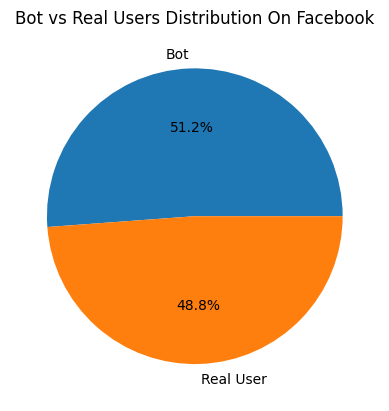

In [ ]:
import matplotlib.pyplot as plt

nodes["account_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.title("Bot vs Real Users Distribution On Facebook")
plt.ylabel("")

plt.show()